# FeederBW Time Series Foundation Models (TSFM) – Tutorial

This notebook serves as a start for exploring time series forcasting of low voltage power grid data with time series foundation models. Feel free to: 
- Run the complete notebook and look at the outcomes
- Extend the notebook code (see also [tutorial.ipynb](tutorial.ipynb)) as you like. 
- Try out the challenges at the end of the notebook. 

**Dataset**: 200 low-voltage distribution feeders in Baden-Württemberg, Germany.  
1-minute resolution measurements, 2023-04 to 2025-03.  
Nature Scientific Data: [Website scientific data](https://www.nature.com/articles/s41597-026-08152-9)

## 1. Setup

The following code is used to make the necessary installations in Google Colab.

In [11]:
!git clone --branch ai-grids-tsfm-workshop-2026 --single-branch https://github.com/KIT-IAI/FeederBW.git
%cd content/FeederBW
!uv sync

Klone nach 'FeederBW' …
fatal: Remote-Branch ai-grids-tsfm-workshop-2026 nicht im Upstream-Repository origin gefunden
[Errno 2] No such file or directory: 'content/FeederBW'
/home/m/Nextcloud/Code/FeederBW
Resolved 69 packages in 19ms
Checked 63 packages in 10ms


In [22]:
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src.download.download import download_data
from src.load.load import load_data
from src.model.forecast import forecast
from src.model.pseudo_measurement_generation import pseudo_measurement_generation

## 2. Downloading the Dataset

The dataset is hosted on [Zenodo](https://zenodo.org/records/17831177).
You can download all files or selective parts using `download_data()`.

For this tutorial we download only metadata and weather. Measurement data was added to the repository already. 

In [23]:
# Skip if you already have the data locally
download_data(files=["feeder_metadata", "weather_data"])
# NOTE (manuel): the measurement data is already available in Git for convenience during the workshop (unzip the files takes too much time in Google Colab)

'data/zenodo' is not empty. Set overwrite=True to remove existing data and download again.


## 3. Loading Data

`load_data()` supports flexible loading with:
- **`feeders`** – list of feeder IDs (1–200)
- **`columns`** – column selection (measurement, weather, metadata columns can be mixed; they are automatically joined)
- **`time_period`** – `(start, end)` as ISO strings or datetime objects
- **`temporal_resolution`** – resample to `"1min"`, `"5min"`, `"15min"`, `"30min"`, `"1h"`, `"1d"`, etc.
- **`aggregation_type`** – per-column aggregation (mean/sum/min/max) used when downsampling
- **`interpolation_type`** – per-column interpolation (linear/forward/backward) used when upsampling

### 3.1 Load measurement data only

In [24]:
meas = load_data(
    feeders=[37, 33], # 97
    columns=["feeder", "timestamp_UTC", "active_power_kW", "apparent_power_kVA"],
    time_period=("2024-01-01T00:00:00", "2024-02-01T00:00:00"),
)
print(f"Shape: {meas.shape}")
meas.head()

Shape: (89282, 4)


feeder,timestamp_UTC,active_power_kW,apparent_power_kVA
i64,"datetime[μs, UTC]",f32,f32
37,2024-01-01 00:00:00 UTC,21.036255,24.252537
37,2024-01-01 00:01:00 UTC,21.307512,24.326874
37,2024-01-01 00:02:00 UTC,22.692511,25.440525
37,2024-01-01 00:03:00 UTC,21.55373,24.340536
37,2024-01-01 00:04:00 UTC,21.551435,24.270559


### 3.2 Resample to hourly resolution

When specifying `temporal_resolution`, you can control per-column aggregation via `aggregation_type`.

In [25]:
meas_hourly = load_data(
    feeders=[37, 33],
    columns=["feeder", "timestamp_UTC", "active_power_kW"],
    time_period=("2024-01-01T00:00:00", "2024-02-01T00:00:00"),
    temporal_resolution="1h",
    aggregation_type={"active_power_kW": "mean"},
)
print(f"Shape: {meas_hourly.shape}")
meas_hourly.head()

Shape: (1490, 3)


feeder,timestamp_UTC,active_power_kW
i64,"datetime[μs, UTC]",f32
33,2024-01-01 00:00:00 UTC,6.50978
33,2024-01-01 01:00:00 UTC,7.313844
33,2024-01-01 02:00:00 UTC,6.156395
33,2024-01-01 03:00:00 UTC,8.506835
33,2024-01-01 04:00:00 UTC,8.984827


### 3.3 Join measurements with weather and metadata

Passing columns from different sources causes `load_data()` to automatically join them on `feeder` and `timestamp_UTC`.

In [26]:
joined = load_data(
    feeders=[37, 33],
    columns=[
        "feeder", "timestamp_UTC",
        "active_power_kW",                   # measurement
        "air_temperature_C",                 # weather
        "housing_units_count",               # metadata
    ],
    time_period=("2024-06-01T00:00:00", "2024-07-01T00:00:00"),
    temporal_resolution="1h",
    aggregation_type={"active_power_kW": "mean", "air_temperature_C": "mean"},
)
print(f"Shape: {joined.shape}")
joined.head(10)

Shape: (1442, 5)


feeder,timestamp_UTC,active_power_kW,air_temperature_C,housing_units_count
i64,"datetime[μs, UTC]",f32,f32,i64
33,2024-06-01 00:00:00 UTC,4.524122,12.50827,0
33,2024-06-01 01:00:00 UTC,4.467181,12.496063,0
33,2024-06-01 02:00:00 UTC,7.655075,12.518555,0
33,2024-06-01 03:00:00 UTC,8.453971,12.405609,0
33,2024-06-01 04:00:00 UTC,6.054786,12.391449,0
33,2024-06-01 05:00:00 UTC,6.110342,12.600372,0
33,2024-06-01 06:00:00 UTC,4.050982,12.772614,0
33,2024-06-01 07:00:00 UTC,4.820944,13.015808,0
33,2024-06-01 08:00:00 UTC,-4.081091,13.415161,0


## 4. Exploring the Data

Let's visualise active power and air temperature for one feeder over a few days.

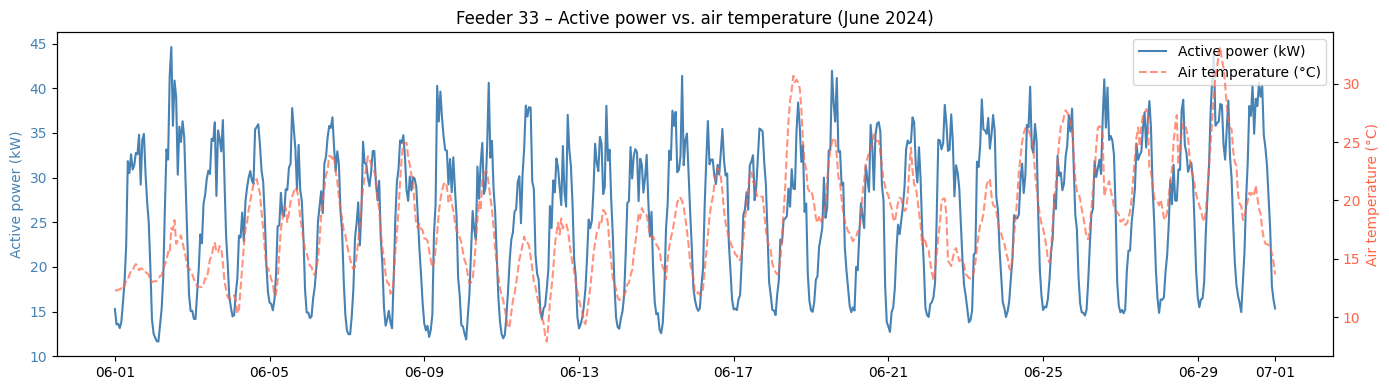

In [27]:
feeder_1 = joined.filter(pl.col("feeder") == 37).sort("timestamp_UTC")
ts = feeder_1["timestamp_UTC"].to_list()
power = feeder_1["active_power_kW"].to_list()
temp = feeder_1["air_temperature_C"].to_list()

fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(ts, power, color="steelblue", label="Active power (kW)")
ax1.set_ylabel("Active power (kW)", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))

ax2 = ax1.twinx()
ax2.plot(ts, temp, color="tomato", linestyle="--", alpha=0.7, label="Air temperature (°C)")
ax2.set_ylabel("Air temperature (°C)", color="tomato")
ax2.tick_params(axis="y", labelcolor="tomato")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
ax1.set_title("Feeder 33 – Active power vs. air temperature (June 2024)")
fig.tight_layout()
plt.show()

### 4.1 Daily load profiles

Aggregate to 15-minute resolution and plot the median daily profile for Feeder 33.

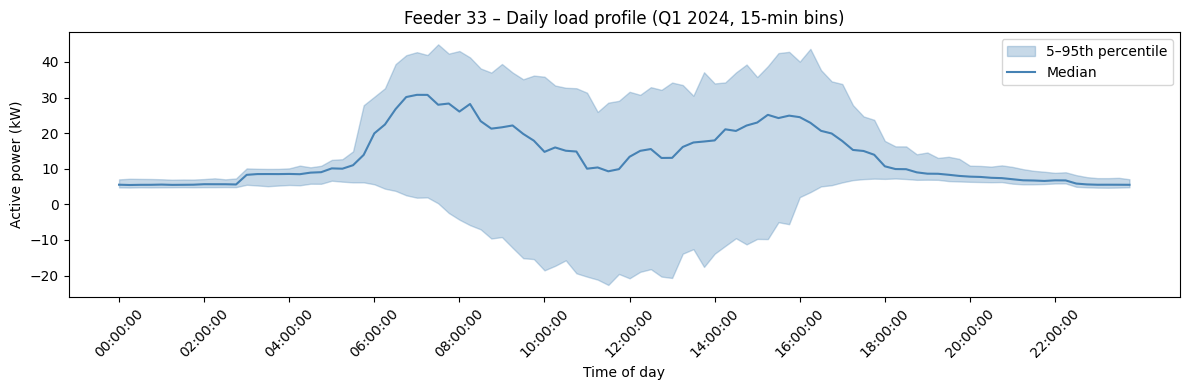

In [28]:
meas_15min = load_data(
    feeders=[33],
    columns=["feeder", "timestamp_UTC", "active_power_kW"],
    time_period=("2024-01-01T00:00:00", "2024-04-01T00:00:00"),
    temporal_resolution="15min",
    aggregation_type={"active_power_kW": "mean"},
)

daily_profile = (
    meas_15min
    .with_columns(pl.col("timestamp_UTC").dt.time().alias("time_of_day"))
    .group_by("time_of_day")
    .agg(
        pl.col("active_power_kW").quantile(0.05).alias("q05"),
        pl.col("active_power_kW").median().alias("median"),
        pl.col("active_power_kW").quantile(0.95).alias("q95"),
    )
    .sort("time_of_day")
)

times = [str(t) for t in daily_profile["time_of_day"].to_list()]
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(times, daily_profile["q05"].to_list(), daily_profile["q95"].to_list(),
                alpha=0.3, color="steelblue", label="5–95th percentile")
ax.plot(times, daily_profile["median"].to_list(), color="steelblue", label="Median")
ax.set_xticks(range(0, len(times), 8))
ax.set_xticklabels(times[::8], rotation=45)
ax.set_xlabel("Time of day")
ax.set_ylabel("Active power (kW)")
ax.set_title("Feeder 33 – Daily load profile (Q1 2024, 15-min bins)")
ax.legend()
fig.tight_layout()
plt.show()

### 4.2 Feeder metadata overview

The metadata CSV contains information about installed DER capacity, consumer types, and load profiles for each feeder.

In [29]:
meta = pl.read_csv("data/zenodo/feeder_metadata.csv")
print(f"Shape: {meta.shape}")
print(meta.columns)
meta.head()

Shape: (1608, 23)
['feeder', 'substation', 'date', 'housing_units_count', 'industry_and_commerce_count', 'storage_heaters_kW', 'heat_pumps_kW', 'electric_heaters_kW', 'hot_water_tanks_kW', 'flow-type_heaters_kW', 'EV_chargers_kW', 'public_lighting_kW', 'other_consumers_kW', 'batteries_kW', 'PV_systems_kW', 'chp_kW', 'g0_general_kWh', 'g1_workdays_kWh', 'g2_evening_kWh', 'g3_continuous_kWh', 'g4_shop_hairdresser_kWh', 'g5_bakery_kWh', 'g6_weekend_kWh']


feeder,substation,date,housing_units_count,industry_and_commerce_count,storage_heaters_kW,heat_pumps_kW,electric_heaters_kW,hot_water_tanks_kW,flow-type_heaters_kW,EV_chargers_kW,public_lighting_kW,other_consumers_kW,batteries_kW,PV_systems_kW,chp_kW,g0_general_kWh,g1_workdays_kWh,g2_evening_kWh,g3_continuous_kWh,g4_shop_hairdresser_kWh,g5_bakery_kWh,g6_weekend_kWh
i64,i64,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,1,"""2023-04-01""",70,11,144.4,2.1,28.8,6.0,42.0,0.0,10.0,254.5,0.0,0.0,10.8,0.048012,3.082029,8.003643,0.0,0.356536,0.0,0.0
1,1,"""2023-08-24""",70,11,144.4,2.1,28.8,6.0,42.0,0.0,10.0,254.5,0.0,0.0,10.8,0.048012,3.074589,8.003643,0.0,0.356536,0.0,0.0
1,1,"""2023-08-28""",70,11,144.4,2.1,28.8,6.0,42.0,0.0,10.0,254.5,0.0,0.0,10.8,0.017759,3.074589,8.003643,0.0,0.366525,0.0,0.0
1,1,"""2023-08-30""",70,11,144.4,2.1,28.8,6.0,42.0,0.0,10.0,254.5,0.0,0.0,10.8,0.017759,3.074589,8.003643,0.0,0.389885,0.0,0.0
1,1,"""2023-09-05""",70,11,144.4,2.1,28.8,6.0,42.0,0.0,10.0,254.5,0.0,0.0,10.8,0.017759,3.134961,8.003643,0.0,0.389885,0.0,0.0


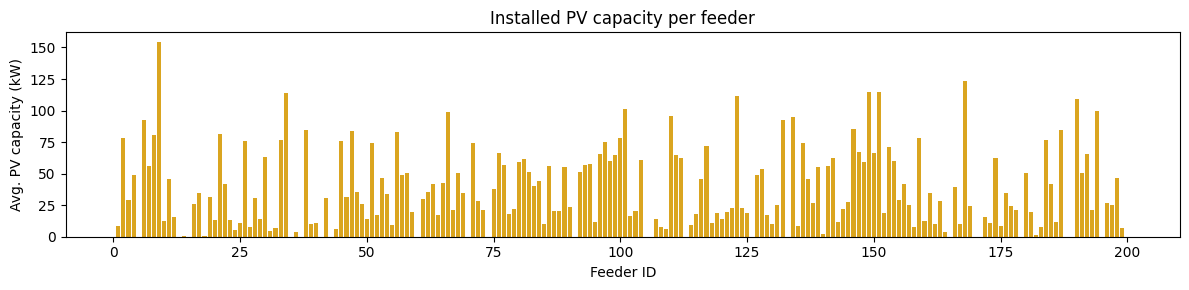

In [30]:
# Distribution of installed PV capacity across feeders
pv_stats = meta.group_by("feeder").agg(pl.col("PV_systems_kW").mean()).sort("feeder")

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(pv_stats["feeder"].to_list(), pv_stats["PV_systems_kW"].to_list(), color="goldenrod", width=0.8)
ax.set_xlabel("Feeder ID")
ax.set_ylabel("Avg. PV capacity (kW)")
ax.set_title("Installed PV capacity per feeder")
fig.tight_layout()
plt.show()

## 5. Forecasting

### 5.1 Naive Forecast

`forecast()` implements a **naive quantile baseline**: for each test day (from `split_date` onwards), the 5th, 50th, and 95th percentile of `target_column` are computed for each `(feeder, time_of_day)` combination using all historically available data.

Metrics returned (per feeder + average):
- **MAE** – Mean Absolute Error on the median forecast
- **Pinball loss** – for each of the three quantiles (q05, q50, q95)
- **Winkler score** – 90% prediction interval quality (lower is better)

In [31]:
data_for_forecast = load_data(
    feeders=[37],
    columns=["feeder", "timestamp_UTC", "active_power_kW"],
    time_period=("2024-01-01T00:00:00", "2024-04-01T00:00:00"),
    temporal_resolution="1h",
    aggregation_type={"active_power_kW": "mean"},
)

forecast_metrics = forecast(
    data=data_for_forecast,
    split_date="2024-03-01",
    target_column="active_power_kW",
)
forecast_metrics

feeder,mae,pinball_q05,pinball_q50,pinball_q95,winkler_score
str,f32,f32,f32,f32,f32
"""37""",2.99257,0.338936,1.496285,0.451982,15.818375
"""average""",2.99257,0.338936,1.496285,0.451982,15.818375


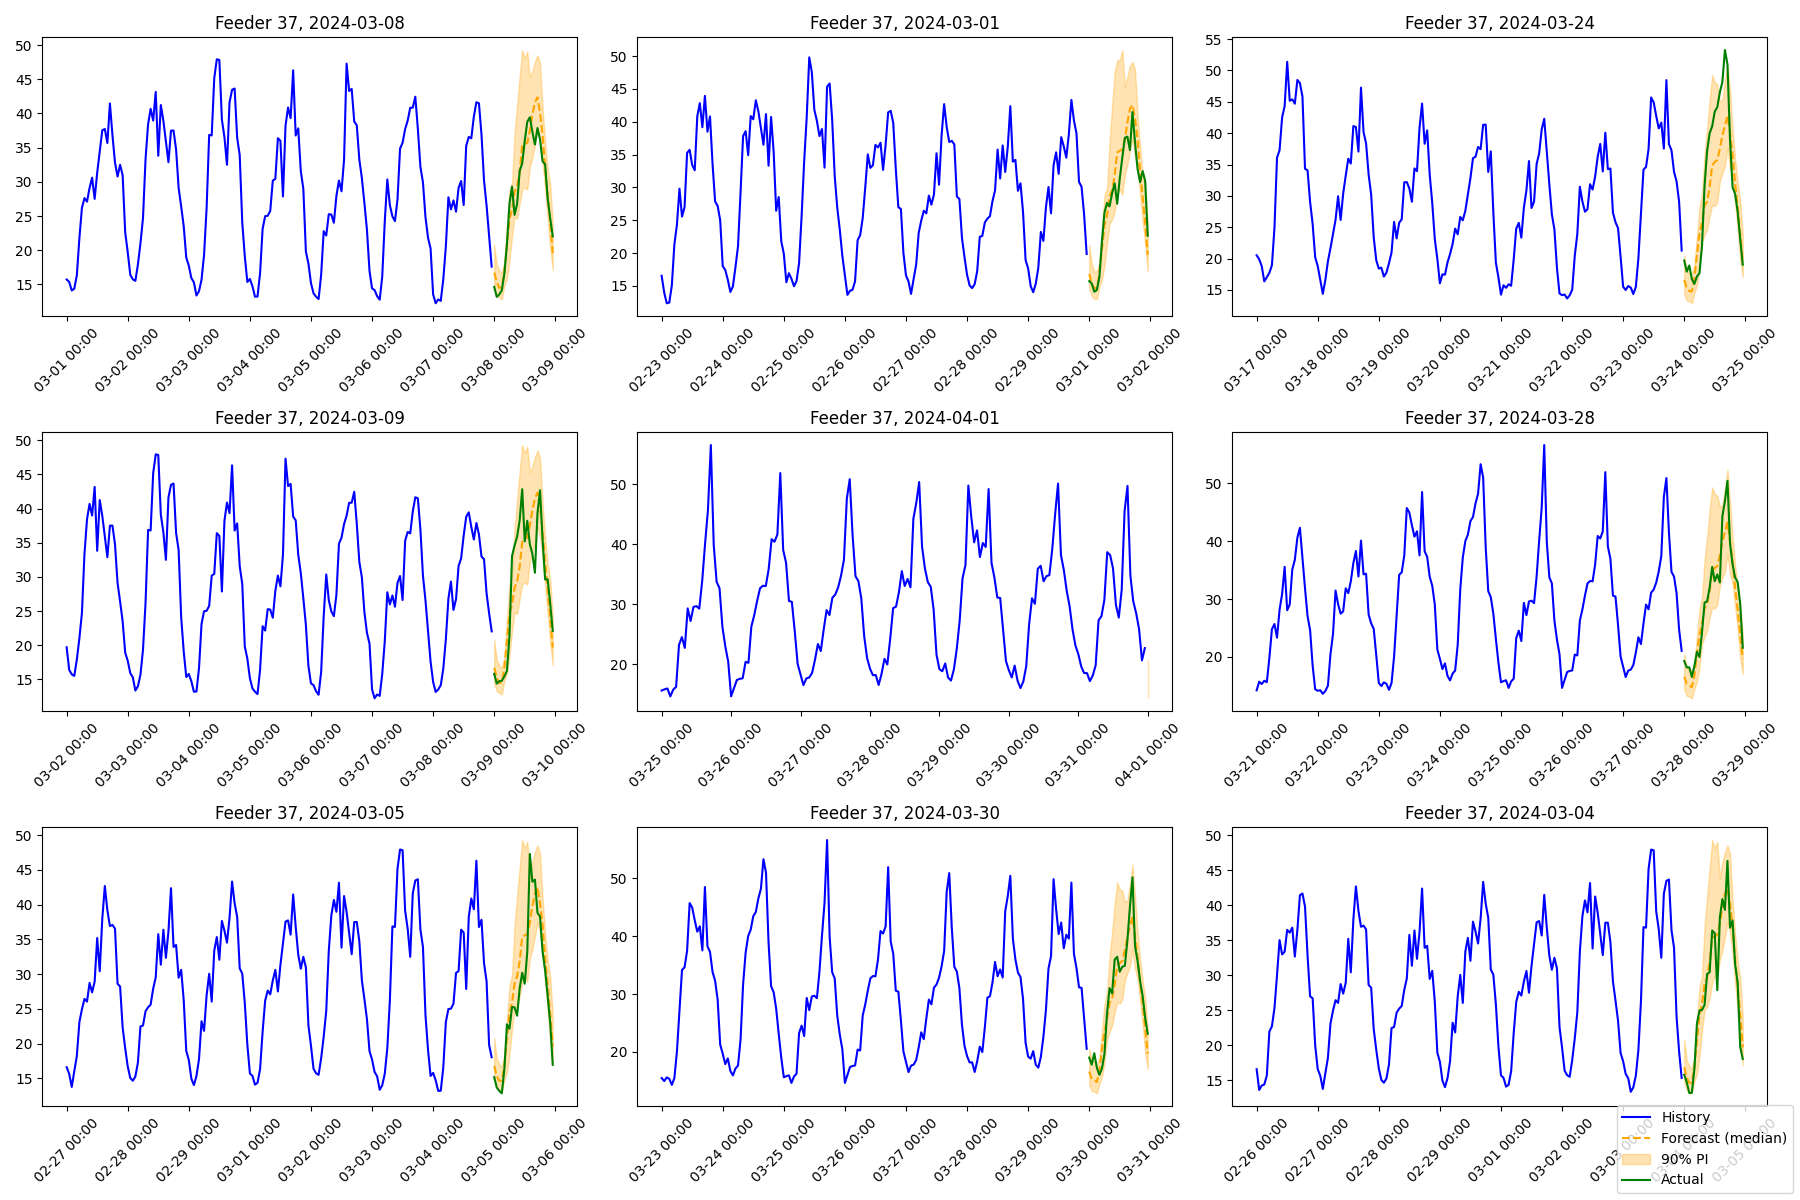

In [34]:
# NOTE (manuel): the subfigures are created randomly from the forecast results. 
from IPython.display import Image
Image("data/forecast_figure.png")

### 5.2 Chronos-2 Forecast

In [33]:
# TODO

## 6. Challenges